# Loan Approval Prediction

**Student:** Soumalya Pal   
**Project:** Major Project — Classification

## Objective
Predict whether a loan application is approved using applicant financial, credit and property-related information.

The workflow covers dataset inspection, class balance, exploratory analysis, preprocessing, Logistic Regression, Decision Tree, Random Forest and SVM models, evaluation metrics, confusion matrix, ROC-AUC and practical banking interpretation.

In [ ]:
# 1. Import Libraries

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, roc_auc_score
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

/home/oai/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-ede447pc because there was an issue with the default path (/home/oai/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


In [ ]:
# 2. Load Dataset

DATA_PATH = Path("loan_approval_dataset.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Place 'loan_approval_dataset.csv' in the same folder as this notebook."
    )

df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip()

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (4269, 13)


,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [ ]:
# 3. Dataset Inspection

print("Columns:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nMissing values:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing"))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTarget distribution:")
display(df["loan_status"].value_counts().to_frame("count"))

Columns:
['loan_id', 'no_of_dependents', 'education', 'self_employed', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value', 'loan_status']

Data types:


,dtype
loan_id,int64
no_of_dependents,int64
education,object
self_employed,object
income_annum,int64
loan_amount,int64
loan_term,int64
cibil_score,int64
residential_assets_value,int64
commercial_assets_value,int64



Missing values:


,missing
loan_id,0
no_of_dependents,0
education,0
self_employed,0
income_annum,0
loan_amount,0
loan_term,0
cibil_score,0
residential_assets_value,0
commercial_assets_value,0



Duplicate rows: 0

Target distribution:


,count
loan_status,
Approved,2656
Rejected,1613


## 4. Exploratory Data Analysis — 12 Visualizations

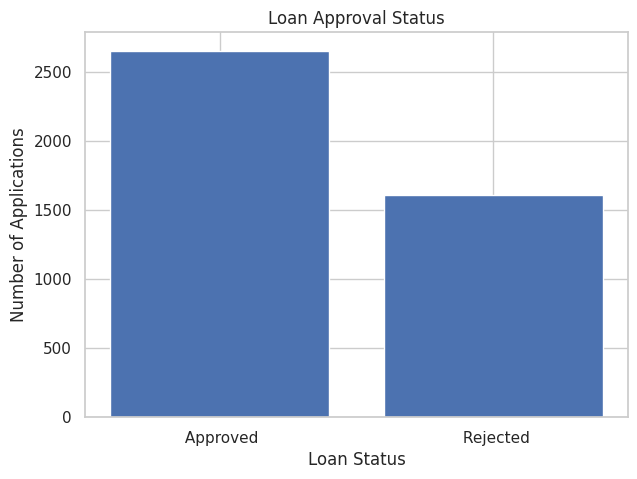

In [ ]:
# EDA 1 — Loan Approval Distribution
counts = df["loan_status"].value_counts()
plt.figure(figsize=(7,5))
plt.bar(counts.index, counts.values)
plt.title("Loan Approval Status")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applications")
plt.show()

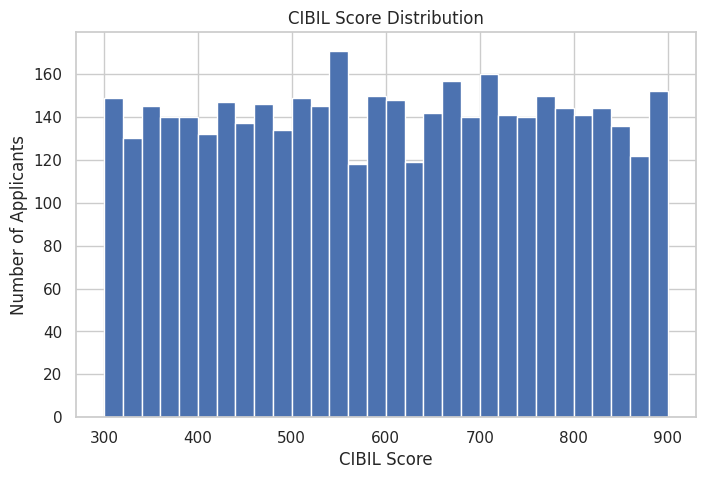

In [ ]:
# EDA 2 — CIBIL Score Distribution
plt.figure(figsize=(8,5))
plt.hist(df["cibil_score"], bins=30)
plt.title("CIBIL Score Distribution")
plt.xlabel("CIBIL Score")
plt.ylabel("Number of Applicants")
plt.show()

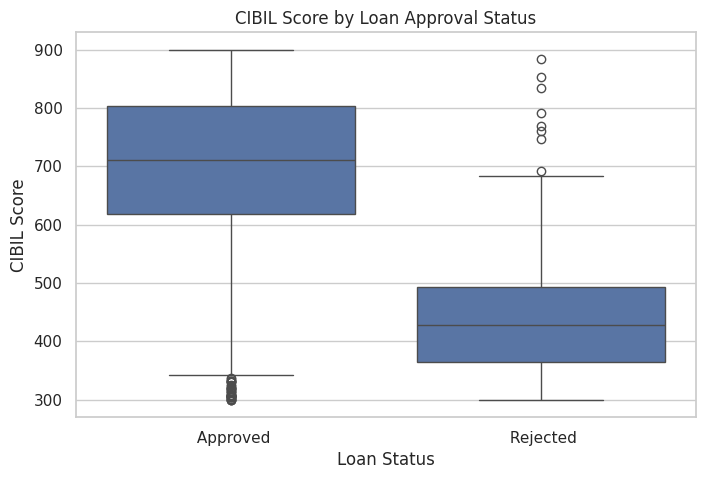

In [ ]:
# EDA 3 — CIBIL Score by Loan Status
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="loan_status", y="cibil_score")
plt.title("CIBIL Score by Loan Approval Status")
plt.xlabel("Loan Status")
plt.ylabel("CIBIL Score")
plt.show()

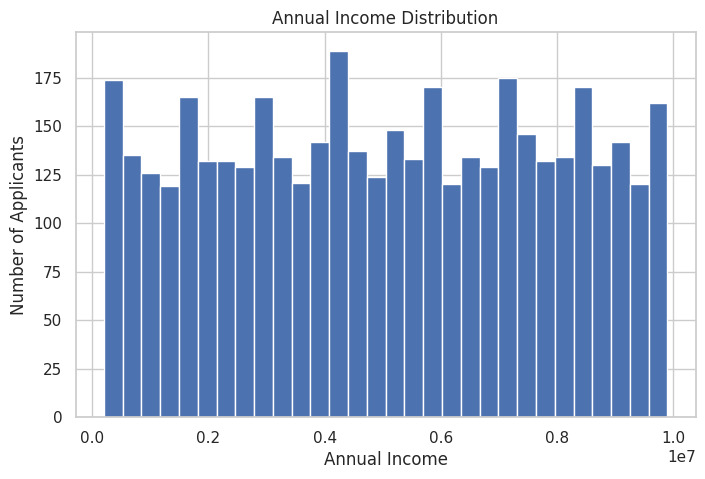

In [ ]:
# EDA 4 — Annual Income Distribution
plt.figure(figsize=(8,5))
plt.hist(df["income_annum"], bins=30)
plt.title("Annual Income Distribution")
plt.xlabel("Annual Income")
plt.ylabel("Number of Applicants")
plt.show()

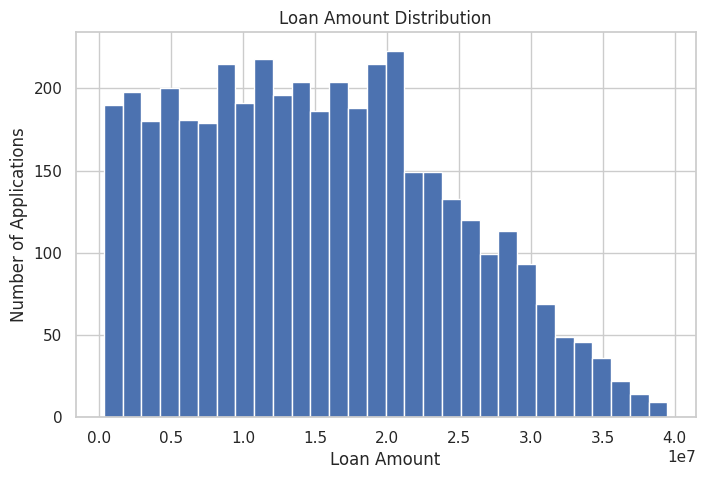

In [ ]:
# EDA 5 — Loan Amount Distribution
plt.figure(figsize=(8,5))
plt.hist(df["loan_amount"], bins=30)
plt.title("Loan Amount Distribution")
plt.xlabel("Loan Amount")
plt.ylabel("Number of Applications")
plt.show()

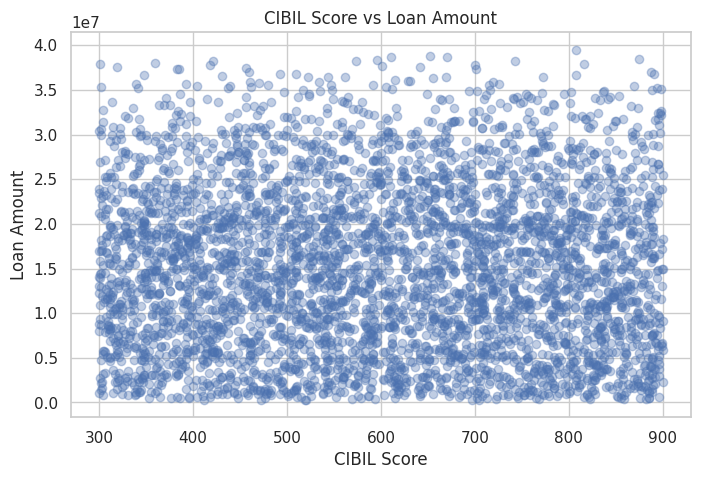

In [ ]:
# EDA 6 — CIBIL Score vs Loan Amount
plt.figure(figsize=(8,5))
plt.scatter(df["cibil_score"], df["loan_amount"], alpha=0.35)
plt.title("CIBIL Score vs Loan Amount")
plt.xlabel("CIBIL Score")
plt.ylabel("Loan Amount")
plt.show()

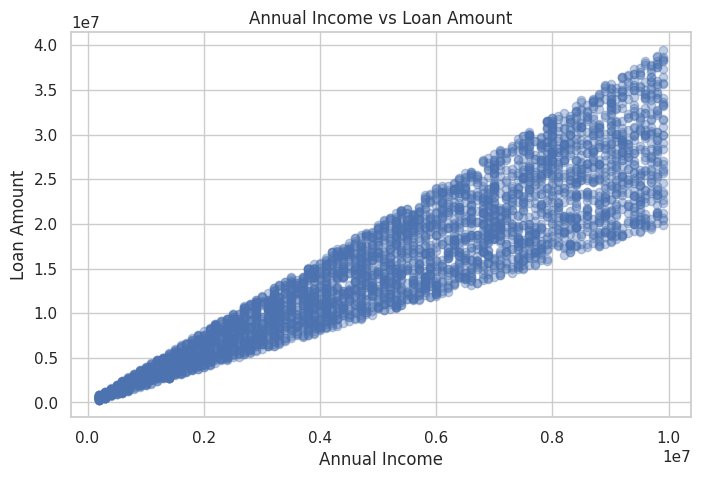

In [ ]:
# EDA 7 — Income vs Loan Amount
plt.figure(figsize=(8,5))
plt.scatter(df["income_annum"], df["loan_amount"], alpha=0.35)
plt.title("Annual Income vs Loan Amount")
plt.xlabel("Annual Income")
plt.ylabel("Loan Amount")
plt.show()

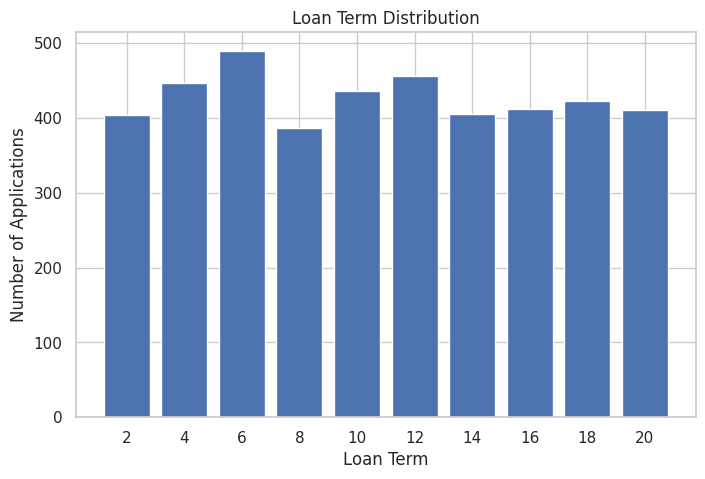

In [ ]:
# EDA 8 — Loan Term Distribution
term_counts = df["loan_term"].value_counts().sort_index()
plt.figure(figsize=(8,5))
plt.bar(term_counts.index.astype(str), term_counts.values)
plt.title("Loan Term Distribution")
plt.xlabel("Loan Term")
plt.ylabel("Number of Applications")
plt.show()

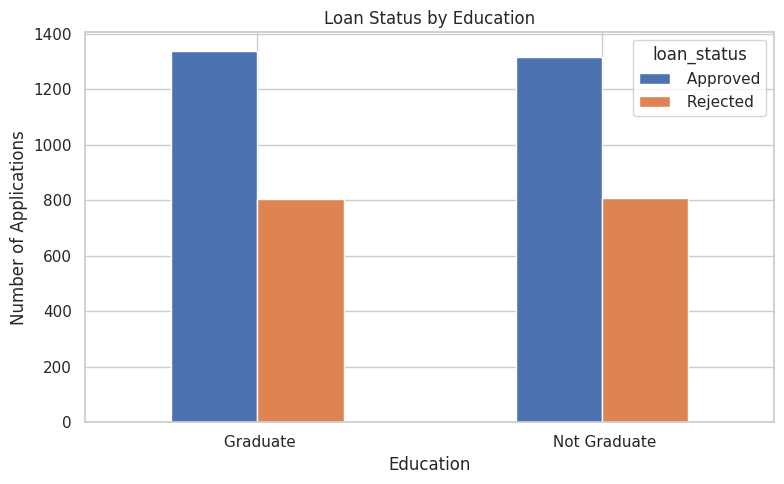

In [ ]:
# EDA 9 — Education vs Loan Status
pd.crosstab(df["education"], df["loan_status"]).plot(kind="bar", figsize=(8,5))
plt.title("Loan Status by Education")
plt.xlabel("Education")
plt.ylabel("Number of Applications")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

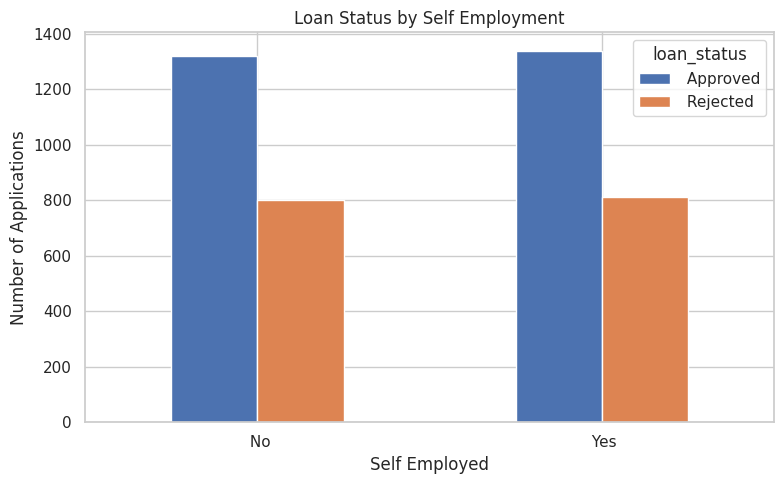

In [ ]:
# EDA 10 — Self Employment vs Loan Status
pd.crosstab(df["self_employed"], df["loan_status"]).plot(kind="bar", figsize=(8,5))
plt.title("Loan Status by Self Employment")
plt.xlabel("Self Employed")
plt.ylabel("Number of Applications")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

<Figure size 1000x500 with 0 Axes>

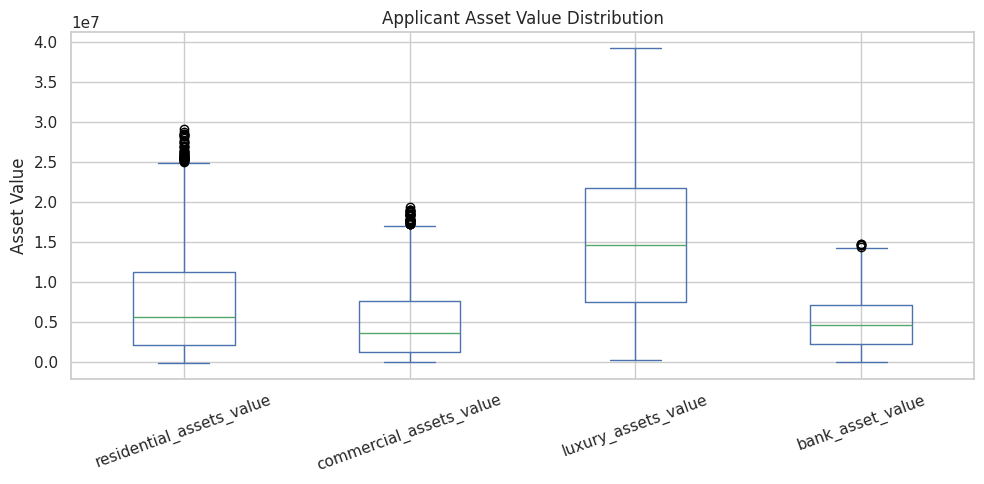

In [ ]:
# EDA 11 — Asset Value Distribution
asset_cols = [
    "residential_assets_value",
    "commercial_assets_value",
    "luxury_assets_value",
    "bank_asset_value"
]
plt.figure(figsize=(10,5))
df[asset_cols].plot(kind="box", figsize=(10,5))
plt.title("Applicant Asset Value Distribution")
plt.ylabel("Asset Value")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

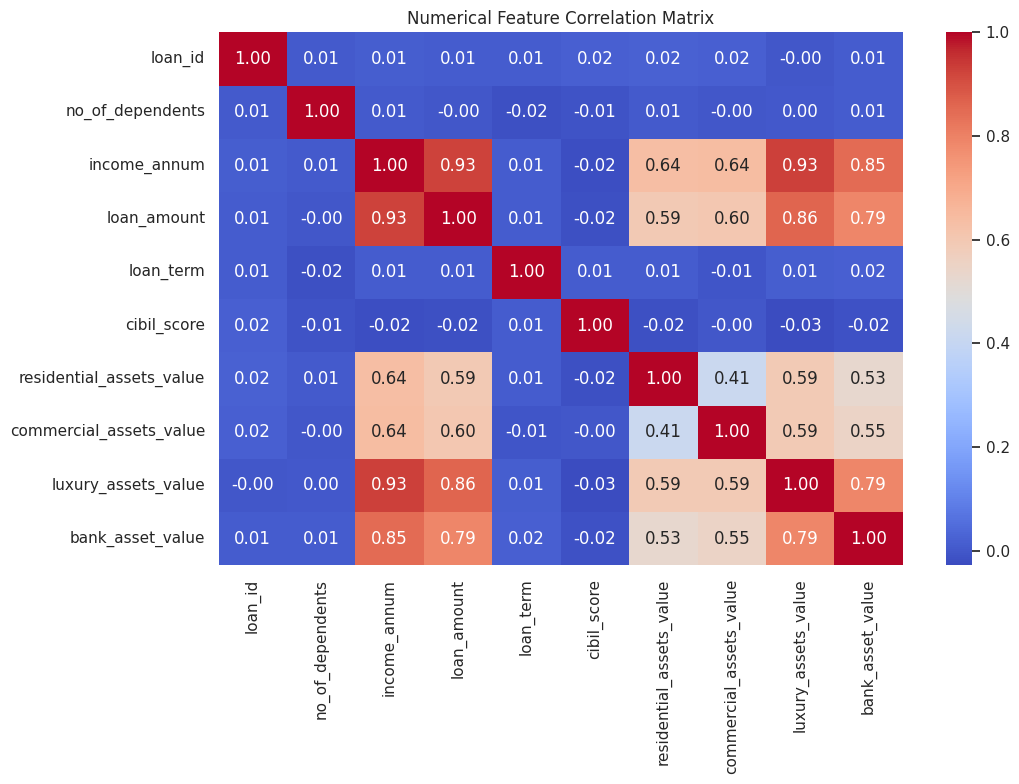

In [ ]:
# EDA 12 — Numerical Correlation Matrix
corr = df.select_dtypes(include=np.number).corr()
plt.figure(figsize=(11,8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Numerical Feature Correlation Matrix")
plt.tight_layout()
plt.show()

## 5. Preprocessing and Model Building

The target is converted to binary values:
- Approved → 1
- Rejected → 0

Numerical variables are median-imputed and standardized. Categorical variables are imputed and one-hot encoded. The preprocessing is placed inside a pipeline to avoid data leakage between training and testing data.

In [ ]:
# 5. Prepare Data and Check Class Balance

df = df.drop_duplicates().reset_index(drop=True)

y = (
    df["loan_status"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({"approved": 1, "rejected": 0})
)

X = df.drop(columns=["loan_status", "loan_id"], errors="ignore")

print("Class distribution:")
display(df["loan_status"].value_counts().to_frame("count"))

print("Class percentage:")
display((df["loan_status"].value_counts(normalize=True) * 100).round(2).to_frame("percentage"))

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Class distribution:


,count
loan_status,
Approved,2656
Rejected,1613


Class percentage:


,percentage
loan_status,
Approved,62.22
Rejected,37.78


Training rows: 3415
Testing rows: 854


## 6. Train and Compare Four Classification Models

In [ ]:
# 6. Model Training

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=8, min_samples_leaf=3, random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=250, min_samples_leaf=2,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "SVM": SVC(probability=True, random_state=RANDOM_STATE)
}

results = []
fitted_models = {}

for name, model in models.items():
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:, 1]

    results.append([
        name,
        accuracy_score(y_test, pred),
        precision_score(y_test, pred),
        recall_score(y_test, pred),
        f1_score(y_test, pred),
        roc_auc_score(y_test, prob)
    ])

    fitted_models[name] = pipe

results_df = pd.DataFrame(
    results,
    columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
).sort_values("F1 Score", ascending=False)

display(results_df.style.format({
    "Accuracy": "{:.3f}",
    "Precision": "{:.3f}",
    "Recall": "{:.3f}",
    "F1 Score": "{:.3f}",
    "ROC-AUC": "{:.3f}"
}))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
1,Decision Tree,0.982,0.973,1.000,0.986,0.993
2,Random Forest,0.980,0.985,0.983,0.984,0.999
3,SVM,0.946,0.958,0.955,0.957,0.988
0,Logistic Regression,0.915,0.921,0.944,0.932,0.973


<Figure size 1100x600 with 0 Axes>

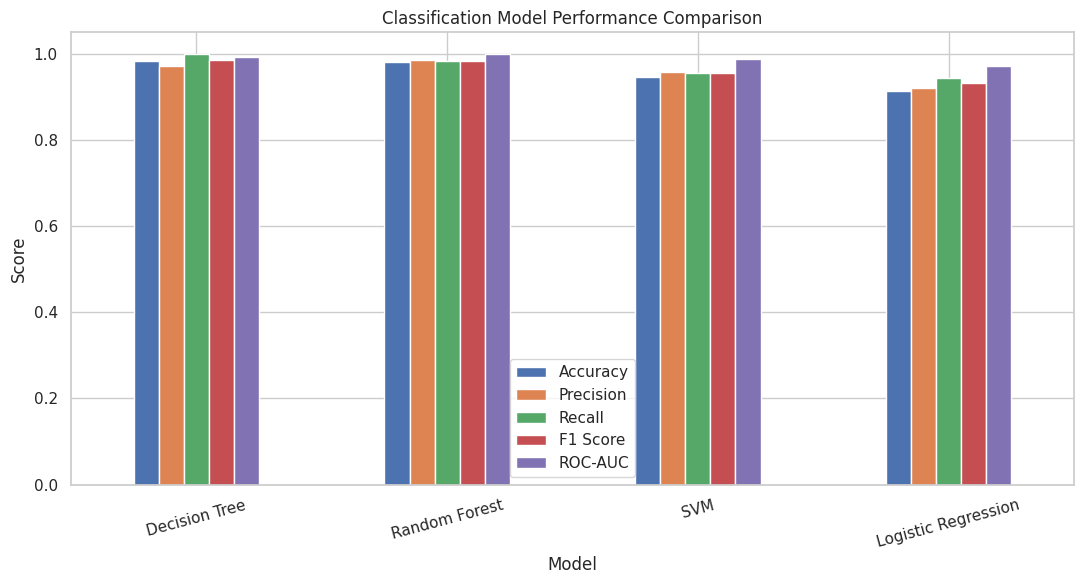

In [ ]:
# 7. Model Performance Comparison

plt.figure(figsize=(11,6))
results_df.set_index("Model")[["Accuracy","Precision","Recall","F1 Score","ROC-AUC"]].plot(
    kind="bar", figsize=(11,6)
)
plt.ylim(0, 1.05)
plt.title("Classification Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Best model based on F1 Score: Decision Tree


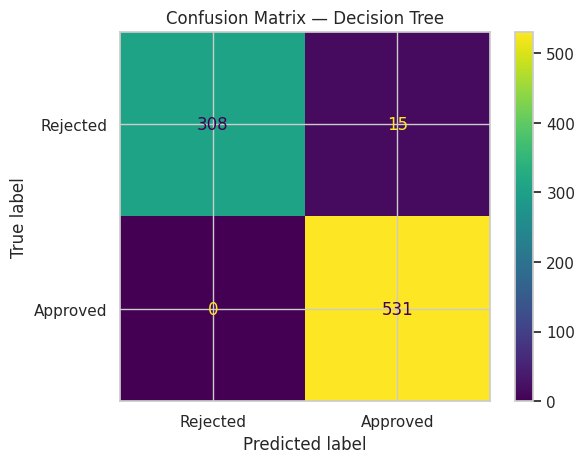

In [ ]:
# 8. Confusion Matrix for the Best Model

best_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_name]
best_pred = best_model.predict(X_test)

print("Best model based on F1 Score:", best_name)

ConfusionMatrixDisplay.from_predictions(
    y_test, best_pred,
    display_labels=["Rejected", "Approved"]
)
plt.title(f"Confusion Matrix — {best_name}")
plt.show()

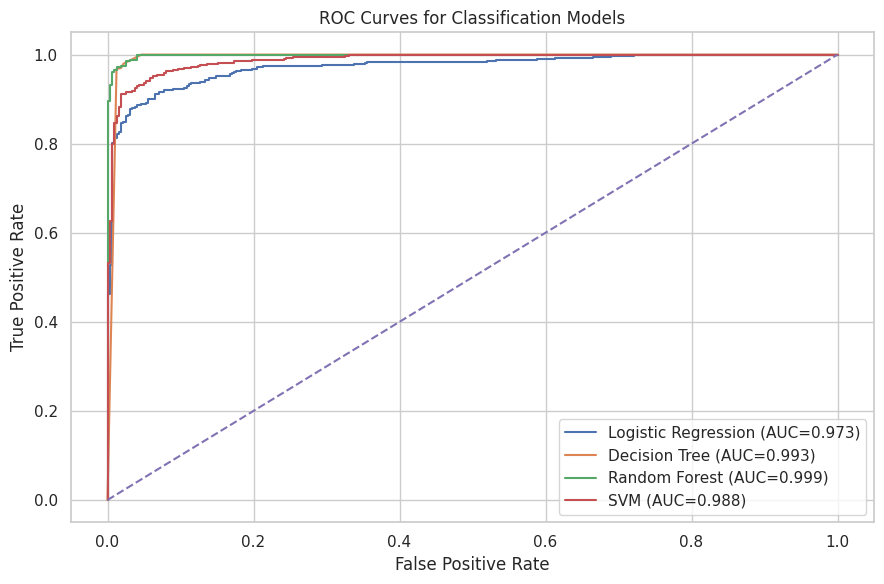

In [ ]:
# 9. ROC Curves and AUC

plt.figure(figsize=(9,6))

for name, model in fitted_models.items():
    probability = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probability)
    auc = roc_auc_score(y_test, probability)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")

plt.plot([0,1], [0,1], "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves for Classification Models")
plt.legend()
plt.tight_layout()
plt.show()

,Feature,Importance
4,num__cibil_score,0.810356
3,num__loan_term,0.061504
2,num__loan_amount,0.028418
7,num__luxury_assets_value,0.017542
1,num__income_annum,0.017394
6,num__commercial_assets_value,0.017310
5,num__residential_assets_value,0.016201
8,num__bank_asset_value,0.014995
0,num__no_of_dependents,0.008474
9,cat__education_ Graduate,0.002016


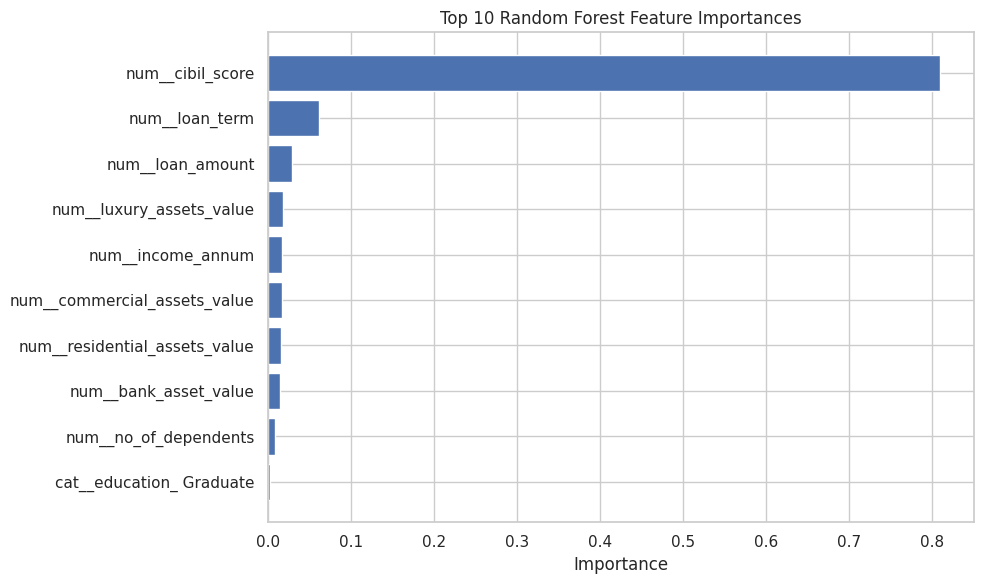

In [ ]:
# 10. Random Forest Feature Importance

rf_pipe = fitted_models["Random Forest"]
rf_preprocessor = rf_pipe.named_steps["preprocessor"]
rf_model = rf_pipe.named_steps["model"]

feature_names = rf_preprocessor.get_feature_names_out()

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False).head(10)

display(feature_importance)

plt.figure(figsize=(10,6))
plot_data = feature_importance.sort_values("Importance")
plt.barh(plot_data["Feature"], plot_data["Importance"])
plt.title("Top 10 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## 7. Banking Interpretation and Conclusion

The selected model is based on the highest F1 Score, which balances precision and recall and is appropriate when both incorrect approvals and incorrect rejections matter.

A bank could use the model as a **decision-support tool** for initial loan screening. Important signals such as credit score, loan characteristics, income and asset information can help prioritize applications for review.

In a real banking environment, the model should be combined with human review, fairness testing, explainability, privacy protection, regulatory controls and monitoring for changes in applicant behaviour or data distribution.